# Overview
This notebook plots ISC across participants

* stack across participants and runs
* stack coefficients across hemisphere for multiple comparisons
* save results in corresponding hemisphere while preserving medial/non-medial wall vertices

### modules

In [1]:
import numpy as np
import pandas as pd
import os, re
from os.path import join
import scipy.stats
from statsmodels.stats.multitest import multipletests
import nibabel as nib
from pathlib import Path


### function: write_gifti

In [2]:
def write_gifti_v2(data, output_fn, template_fn):
    gii = nib.load(template_fn)
    for i in np.arange(gii.numDA):
        gii.remove_gifti_data_array(0)
    gda = nib.gifti.GiftiDataArray(data)
    gii.add_gifti_data_array(gda)
    # nib.gifti.write(gii, output_fn)
    gii.to_filename(output_fn)

### parameters

In [3]:
suma_dir = '/dartfs/rc/lab/H/HaxbyLab/heejung/data/niml'
main_dir = f'/dartfs/rc/lab/H/HaxbyLab/heejung/results/revision/isc'

# LOCAL ____________________________________
suma_dir = '/Users/h/suma-fsaverage6/'
main_dir = '/Volumes/heejung'
results_dir = os.path.join(main_dir, 'results', 'revision', 'isc' )
alignment = 'ws'
runs = [1, 2, 3, 4]
hemis = ['lh', 'rh']
pca_comp = 40
fmri_durs = {1: 374, 2: 346, 3: 377, 4: 412}
n_samples = 1509
n_vertices = 40962
n_medial = {'lh': 3486, 'rh': 3491}
subjects = ['sub-rid000001', 'sub-rid000005', 'sub-rid000006',
            'sub-rid000009', 'sub-rid000012', 'sub-rid000014',
            'sub-rid000017', 'sub-rid000019', 'sub-rid000024',
            'sub-rid000027', 'sub-rid000031', 'sub-rid000032',
            'sub-rid000033', 'sub-rid000034', 'sub-rid000036',
            'sub-rid000037', 'sub-rid000038', 'sub-rid000041']


# Run locally

# plot results in fslr

plot t-test results in surfplots, Freesurfer surface plots

In [4]:
from neuromaps.datasets import fetch_fsaverage, fetch_fslr
import numpy as np
from surfplot import Plot
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import colors
from os.path import join
import nibabel as nib
surfaces = fetch_fsaverage()
lh, rh = surfaces['inflated']
# main_dir = '/Volumes/life-encoding'
# main_dir = '/Users/h/Downloads'
alignment = 'ws'

In [5]:
def fsaverage_to_fslr_and_plot(Lfname, Rfname, key, cmap='inferno', max=.20):
    from neuromaps.datasets import fetch_fslr
    from neuromaps.transforms import fsaverage_to_fslr
    giiL = nib.load(Lfname)
    giiR = nib.load(Rfname)
    L_fslr = fsaverage_to_fslr(giiL, target_density='32k', hemi='L', method='linear')
    R_fslr = fsaverage_to_fslr(giiR, target_density='32k', hemi='R', method='linear')
    
    surfaces_fslr = fetch_fslr()
    lh_fslr, rh_fslr = surfaces_fslr['inflated']

    color_range = (0.0001, max)
    p = Plot(surf_lh=lh_fslr, 
             surf_rh=rh_fslr, 
             size=(1000, 200), 
             zoom=1.2, layout='row', 
             views=['lateral', 'medial', 'ventral', 'posterior'], 
             mirror_views=True, brightness=.7)
    p.add_layer({'left': L_fslr[0], 
                'right': R_fslr[0]}, 
                cmap=cmap, cbar=True,
                color_range=color_range,
                cbar_label=key
                ) # YlOrRd_r
    cbar_kws = dict(outer_labels_only=True, pad=.02, n_ticks=2, decimals=3)
    fig = p.build(cbar_kws=cbar_kws)
    # fig.show()
    return(fig)


In [6]:
import os
import shutil
from neuromaps import datasets

# 1. Force delete the entire atlas directory
atlas_path = '/Users/h/neuromaps-data/atlases/fsaverage'
if os.path.exists(atlas_path):
    print(f"Removing corrupted directory: {atlas_path}")
    shutil.rmtree(atlas_path)

# 2. Re-download
print("Attempting fresh download...")
datasets.fetch_atlas('fsaverage', density='41k')

# 3. Inspect the file content immediately
target_file = os.path.join(atlas_path, 'tpl-fsaverage_den-41k_hemi-L_sphere.surf.gii')

if os.path.exists(target_file):
    with open(target_file, 'r', errors='ignore') as f:
        first_line = f.readline()
        print(f"\nFile Header Check: {first_line[:50]}")
        
        if "<?xml" in first_line:
            print("✅ SUCCESS: Found valid XML header.")
        elif "<!DOCTYPE html" in first_line or "<html" in first_line:
            print("❌ FAILURE: Downloaded an HTML error page instead of data.")
        else:
            print("❌ FAILURE: Unknown file format or empty file.")

Removing corrupted directory: /Users/h/neuromaps-data/atlases/fsaverage
Attempting fresh download...


Downloaded 5070848 of 6550379 bytes (77.4%,    0.3s remaining)


File Header Check: <?xml version="1.0" encoding="UTF-8"?>

✅ SUCCESS: Found valid XML header.


 ...done. (3 seconds, 0 min)
Extracting data from /Users/h/neuromaps-data/9e29c30a00cc86995f334ba48854d362/fsaverage41k.tar.gz..... done.


# load and stack data

In [7]:
hemisphere = 'lh'
run_stack = []
for run in [1,2,3,4]:
    sub_stack = []
    for subject in subjects:
        sub_data = np.load(f'{results_dir}/subjectwise-ISC_{subject}_HAcommon_run-{run}_{hemisphere}.npy')
        sub_stack.append(sub_data)
    run_avg = np.mean(np.vstack(sub_stack), axis=0)
    run_stack.append(run_avg)
hemi_mean = np.mean(np.vstack(run_stack), axis=0)
stats = np.zeros((n_vertices))

medial_mask = np.load(os.path.join(main_dir, 'data', 'niml',
                                f'fsaverage6_medial_{hemisphere}.npy'))
assert np.sum(medial_mask) == n_medial[hemisphere]
cortical_vertices = ~medial_mask # boolean (true for non-medials, false for medials)
cortical_coords = np.where(cortical_vertices)[0] # returns indices of non-medials
print(f"number of non-medial vertices: {len(cortical_coords)}")
stats[cortical_coords] = hemi_mean

save_fname = f"{main_dir}/results/revision/isc_group/isc_hemi-{hemisphere}_mean.gii"
write_gifti_v2(stats.astype(np.float32),
template_fn = os.path.join(suma_dir, f"{hemisphere}.pial.gii"), 
output_fn = save_fname)
print(f'{stats.shape}')

number of non-medial vertices: 37476
(40962,)


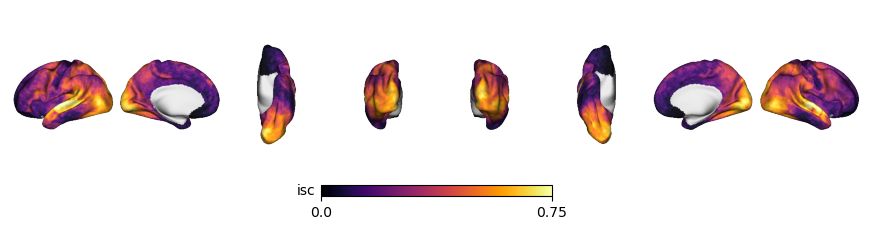

In [8]:
alignment = 'ws'
results_dir = '/Users/h/Downloads'
save_dir = '/Users/h/Documents/projects_local/life-encoding/figure/revision/isc_group'
Path(save_dir).mkdir(parents=True, exist_ok=True)


iscLfname = f"{results_dir}/isc_hemi-lh_mean.gii"
iscRfname = f"{results_dir}/isc_hemi-rh_mean.gii"
feature = 'isc'
fig = fsaverage_to_fslr_and_plot(iscLfname, iscRfname, feature, cmap='inferno', max=.75)

fig.savefig(join(save_dir, f"isc.png"), dpi=300)